In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv("../data/mini_project_1_data.csv")

print(df.shape)

(35680, 30)


In [2]:
df.describe()

,ID,timedelta,shares,n_tokens_title,n_tokens_content,n_unique_tokens,n_non_stop_words,n_non_stop_unique_tokens,num_hrefs,num_self_hrefs,...,num_keywords,kw_min_min,kw_max_min,kw_avg_min,kw_min_max,kw_max_max,kw_avg_max,kw_min_avg,kw_max_avg,kw_avg_avg
count,35680.000000,35680.000000,35680.000000,35680.000000,35680.000000,35680.000000,35680.000000,35680.000000,34959.000000,34959.000000,...,35680.000000,35680.000000,35680.000000,35680.000000,35680.000000,35680.000000,35680.000000,35680.000000,35680.000000,35680.000000
mean,19823.468918,354.523234,3402.054961,10.395432,545.995123,0.530461,0.970263,0.672738,10.866358,3.282531,...,7.220095,26.169703,1142.296851,310.297441,13533.498851,752318.562220,259143.787814,1115.670961,5637.977838,3130.799667
std,11452.292291,214.301086,11934.878541,2.114600,469.550052,0.136935,0.169862,0.153881,11.260971,3.834065,...,1.909604,69.705812,3844.829034,616.961660,57623.779316,214391.922961,135080.424060,1136.741358,6026.965362,1311.012948
min,0.000000,8.000000,4.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,1.000000,-1.000000,0.000000,-1.000000,0.000000,0.000000,0.000000,-1.000000,0.000000,0.000000
25%,9890.750000,163.000000,946.000000,9.000000,247.000000,0.471030,1.000000,0.625912,4.000000,1.000000,...,6.000000,-1.000000,445.000000,141.440476,0.000000,843300.000000,172595.650000,0.000000,3559.646658,2379.762290
50%,19801.500000,339.000000,1400.000000,10.000000,410.000000,0.539011,1.000000,0.690323,8.000000,3.000000,...,7.000000,-1.000000,658.000000,235.428571,1400.000000,843300.000000,244133.333333,1020.667532,4348.584651,2867.991456
75%,29788.250000,543.000000,2800.000000,12.000000,716.000000,0.608203,1.000000,0.754036,14.000000,4.000000,...,9.000000,4.000000,1000.000000,357.000000,7800.000000,843300.000000,330980.000000,2058.093423,6015.434738,3595.530145
max,39643.000000,731.000000,843300.000000,23.000000,8474.000000,1.000000,1.000000,1.000000,304.000000,116.000000,...,10.000000,377.000000,298400.000000,42827.857143,843300.000000,843300.000000,843300.000000,3610.124972,298400.000000,43567.659946


In [3]:
missing_summary = (
    df.isnull()
    .sum()
    .to_frame("Missing Count")
    .assign(Missing_Percentage=lambda x: x["Missing Count"] / len(df) * 100)
    .query("`Missing Count` > 0")
    .sort_values("Missing_Percentage", ascending=False)
)

display(missing_summary)

,Missing Count,Missing_Percentage
num_videos,16755,46.959081
data_channel,5462,15.308296
num_imgs,1419,3.977018
num_self_hrefs,721,2.020740
num_hrefs,721,2.020740
self_reference_min_shares,721,2.020740
self_reference_max_shares,721,2.020740
self_reference_avg_shares,721,2.020740


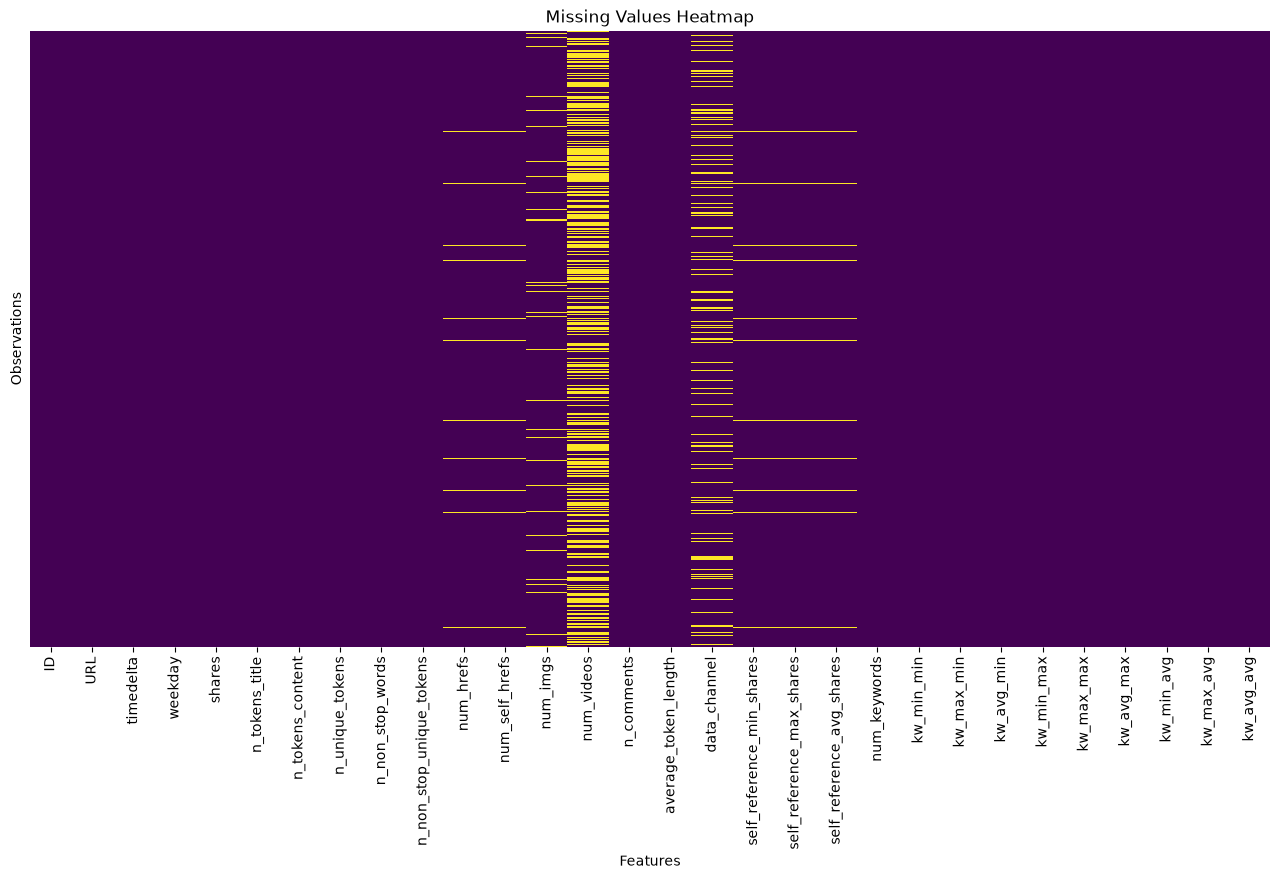

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(16, 8))

sns.heatmap(df.isnull(), cbar=False, yticklabels=False, cmap="viridis")

plt.title("Missing Values Heatmap")
plt.xlabel("Features")
plt.ylabel("Observations")
plt.show()

In [5]:
missing_summary = (
    df.isnull()
    .sum()
    .to_frame("Missing Count")
    .assign(Missing_Percentage=lambda x: x["Missing Count"] / len(df) * 100)
    .query("`Missing Count` > 0")
    .sort_values("Missing_Percentage", ascending=False)
)

display(missing_summary)

,Missing Count,Missing_Percentage
num_videos,16755,46.959081
data_channel,5462,15.308296
num_imgs,1419,3.977018
num_self_hrefs,721,2.020740
num_hrefs,721,2.020740
self_reference_min_shares,721,2.020740
self_reference_max_shares,721,2.020740
self_reference_avg_shares,721,2.020740


In [6]:
import pandas as pd
import textwrap

categorical_vars = df.select_dtypes(
    include=["object", "category", "bool", "string"]
).columns.tolist()

quantitative_vars = df.select_dtypes(
    include=["number"]
).columns.tolist()

temporal_vars = df.select_dtypes(
    include=["datetime", "datetimetz", "timedelta"]
).columns.tolist()

print("Categorical variables:")
print(textwrap.fill(", ".join(categorical_vars), width=80))

print("\nQuantitative variables:")
print(textwrap.fill(", ".join(quantitative_vars), width=80))

print("\nTemporal variables:")
print(textwrap.fill(", ".join(temporal_vars), width=80))

Categorical variables:
URL, weekday, data_channel

Quantitative variables:
ID, timedelta, shares, n_tokens_title, n_tokens_content, n_unique_tokens,
n_non_stop_words, n_non_stop_unique_tokens, num_hrefs, num_self_hrefs, num_imgs,
num_videos, n_comments, average_token_length, self_reference_min_shares,
self_reference_max_shares, self_reference_avg_shares, num_keywords, kw_min_min,
kw_max_min, kw_avg_min, kw_min_max, kw_max_max, kw_avg_max, kw_min_avg,
kw_max_avg, kw_avg_avg

Temporal variables:



# Exploration of distribution of data variables

## num_videos and num_imgs

In [7]:
count_1 = df["num_videos"].isnull().sum()
count_2 = df["num_imgs"].isnull().sum()

print(f"Out of {len(df):,} articles:")
print(f"- {count_1:,} ({count_1 / len(df) * 100:.2f}%) have missing values for num_videos.")
print(f"- {count_2:,} ({count_2 / len(df) * 100:.2f}%) have missing values for num_imgs.")

Out of 35,680 articles:
- 16,755 (46.96%) have missing values for num_videos.
- 1,419 (3.98%) have missing values for num_imgs.


In [8]:
count = (df["num_videos"] == 0).sum()
percentage = (df["num_videos"] == 0).mean() * 100

print(f"Out of {len(df):,} articles, {count:,} ({percentage:.2f}%) contain no videos.")

Out of 35,680 articles, 11,894 (33.34%) contain no videos.


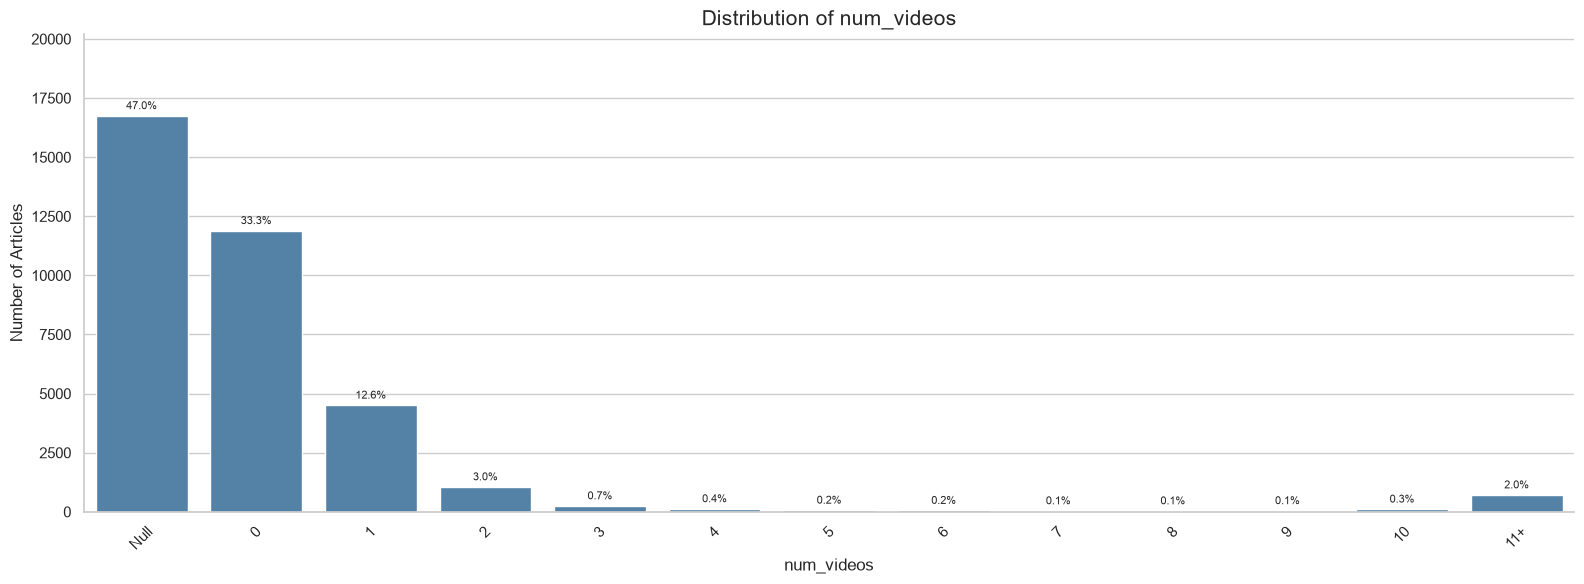

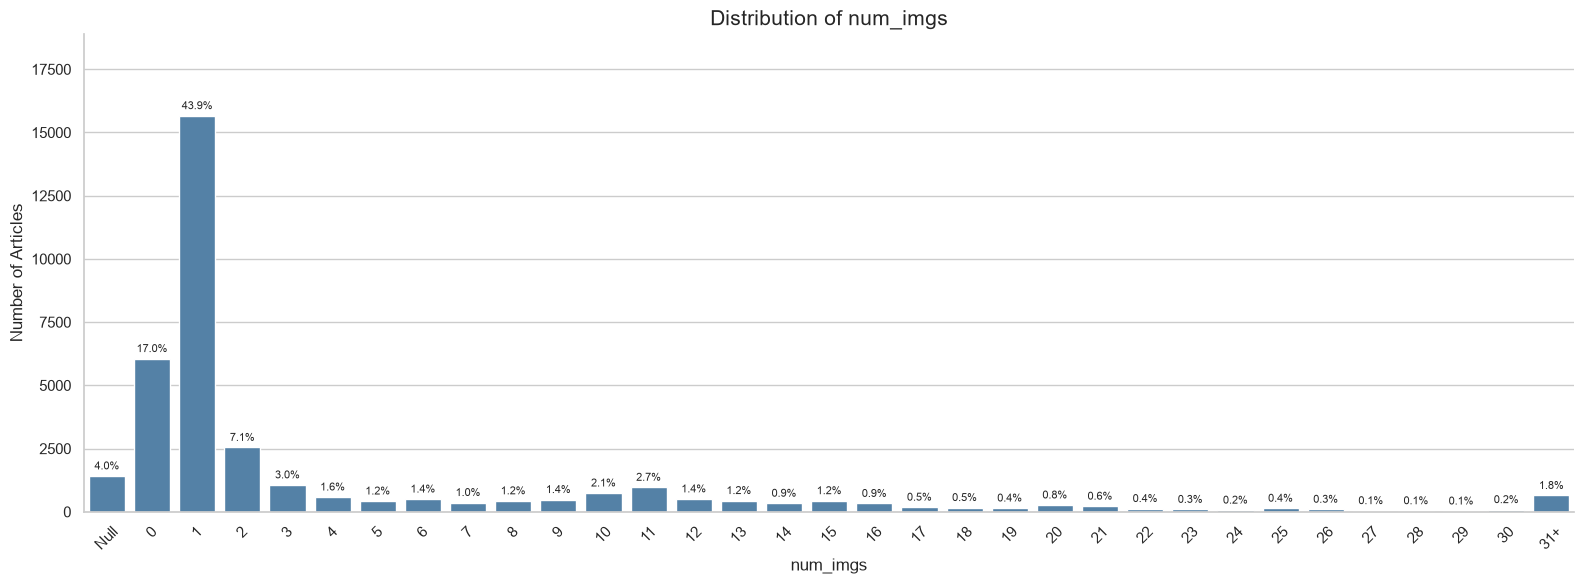

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

sns.set_theme(style="whitegrid")

for col, max_count in [("num_videos", 10), ("num_imgs", 30)]:

    plt.figure(figsize=(16, 6))

    # Group values above the specified maximum
    data = df[col].apply(
        lambda x: "Null" if pd.isna(x)
        else f"{max_count + 1}+" if x > max_count
        else str(int(x))
    )

    order = (
        ["Null"]
        + [str(i) for i in range(max_count + 1)]
        + [f"{max_count + 1}+"]
    )

    ax = sns.countplot(
        x=data,
        order=order,
        color="steelblue"
    )

    # Add percentage labels above bars
    for container in ax.containers:
        labels = [
            f"{bar.get_height() / len(df) * 100:.1f}%"
            if bar.get_height() > 0 else ""
            for bar in container
        ]
        ax.bar_label(container, labels=labels, padding=3, fontsize=8)

    ax.set_title(f"Distribution of {col}", fontsize=15)
    ax.set_xlabel(col)
    ax.set_ylabel("Number of Articles")

    plt.xticks(rotation=45)
    ax.set_ylim(0, ax.get_ylim()[1] * 1.15)

    sns.despine()
    plt.tight_layout()
    plt.show()

## n_comments

In [10]:
count = df["n_comments"].isnull().sum()

print(f"Out of {len(df):,} articles:")
print(f"- {count:,} ({count / len(df) * 100:.2f}%) have missing values for n_comments.")

Out of 35,680 articles:
- 0 (0.00%) have missing values for n_comments.


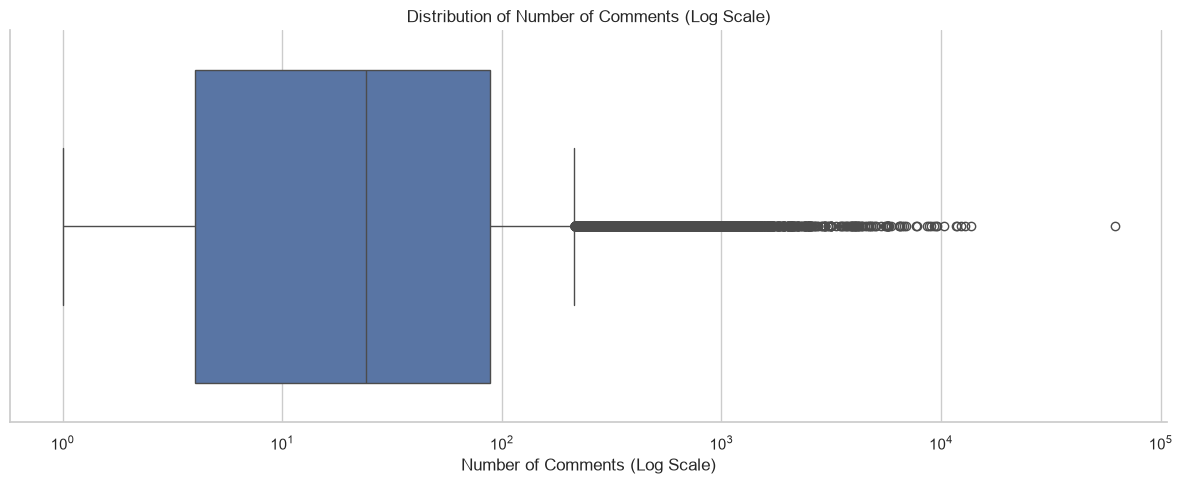

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

# Exclude zeros and nulls
comments = df.loc[df["n_comments"] > 0, "n_comments"]

plt.figure(figsize=(12, 5))

sns.boxplot(x=comments)
plt.xscale("log")

plt.title("Distribution of Number of Comments (Log Scale)")
plt.xlabel("Number of Comments (Log Scale)")

sns.despine()
plt.tight_layout()
plt.show()

## `n_comments` vs `timedelta`

Scatter plot excluding the single article with the largest number of comments **for visualization only**; the original `df` remains unchanged.

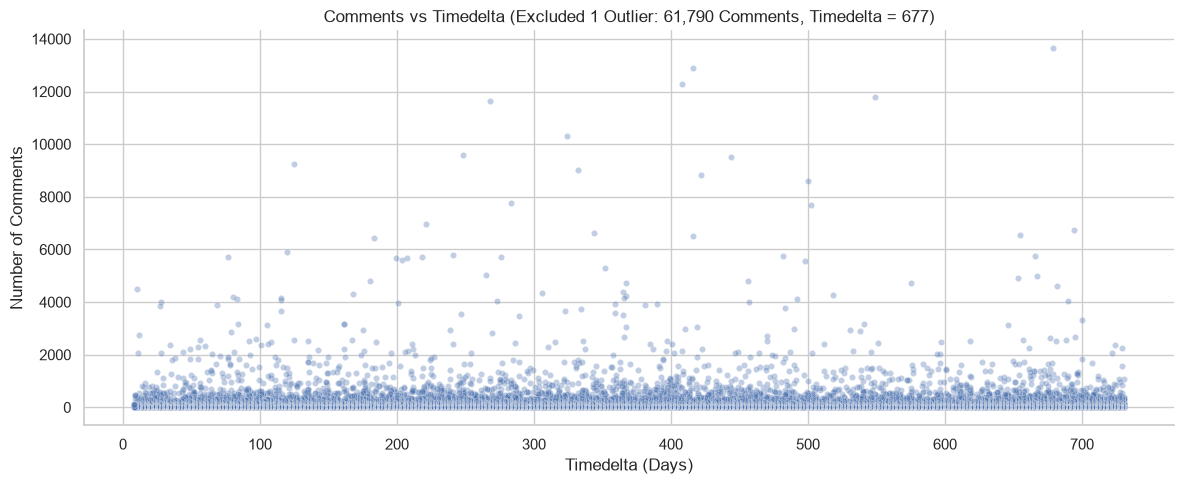

In [12]:
df_plot = df.drop(index=df["n_comments"].idxmax())
outlier = df.loc[df["n_comments"].idxmax()]

plt.figure(figsize=(12, 5))
sns.scatterplot(data=df_plot, x="timedelta", y="n_comments", alpha=0.35, s=20)
plt.title(
    f"Comments vs Timedelta (Excluded 1 Outlier: "
    f"{outlier['n_comments']:,.0f} Comments, Timedelta = {outlier['timedelta']:g})"
)
plt.xlabel("Timedelta (Days)")
plt.ylabel("Number of Comments")
sns.despine()
plt.tight_layout()
plt.show()

## Article text features

`n_tokens_title` and `n_tokens_content` measure word counts; `n_unique_tokens`, `n_non_stop_words`, and `n_non_stop_unique_tokens` are documented as rates. Check unexpected values before making modeling decisions.

In [13]:
text_features = [
    "n_tokens_title", "n_tokens_content", "n_unique_tokens",
    "n_non_stop_words", "n_non_stop_unique_tokens"
]
summary = df[text_features].describe().T
summary["missing"] = df[text_features].isna().sum()
summary["skewness"] = df[text_features].skew()
q1, q3 = df[text_features].quantile(0.25), df[text_features].quantile(0.75)
iqr = q3 - q1
summary["outliers_1_5_iqr"] = ((df[text_features] < q1 - 1.5 * iqr) | (df[text_features] > q3 + 1.5 * iqr)).sum()
display(summary.round(4))

,count,mean,std,min,25%,50%,75%,max,missing,skewness,outliers_1_5_iqr
n_tokens_title,35680.0,10.3954,2.1146,2.0,9.0000,10.0000,12.0000,23.0,0,0.1710,140
n_tokens_content,35680.0,545.9951,469.5501,0.0,247.0000,410.0000,716.0000,8474.0,0,2.9883,1705
n_unique_tokens,35680.0,0.5305,0.1369,0.0,0.4710,0.5390,0.6082,1.0,0,-1.4611,1460
n_non_stop_words,35680.0,0.9703,0.1699,0.0,1.0000,1.0000,1.0000,1.0,0,-5.5373,2536
n_non_stop_unique_tokens,35680.0,0.6727,0.1539,0.0,0.6259,0.6903,0.7540,1.0,0,-2.4095,1572


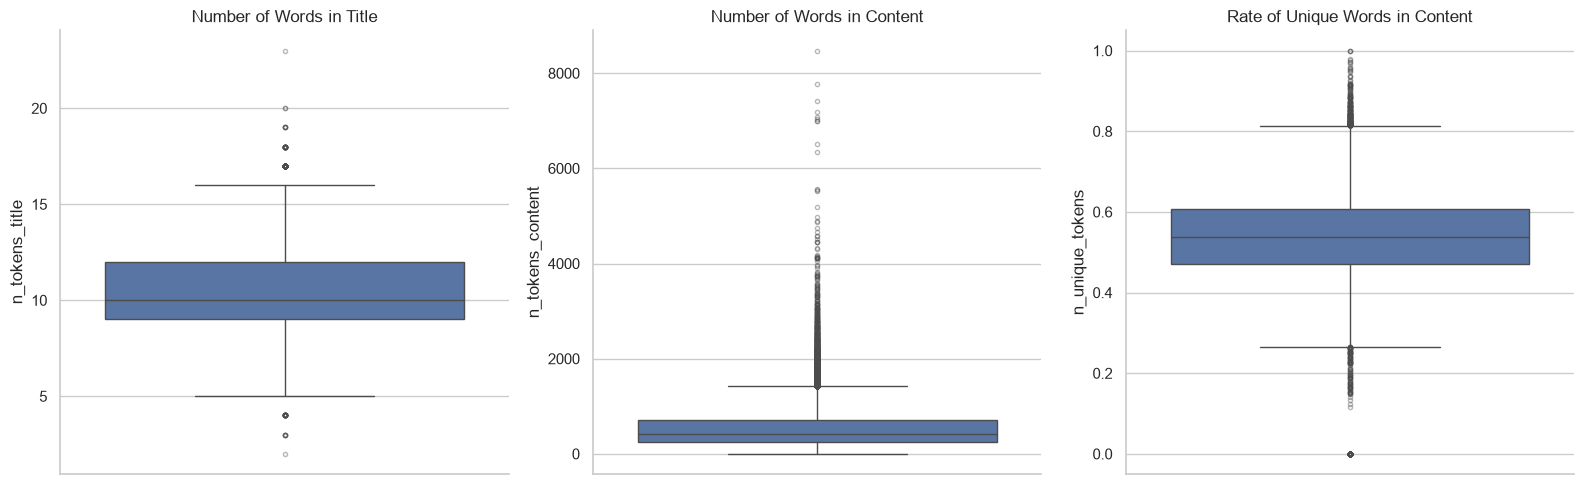

In [14]:
columns = ["n_tokens_title", "n_tokens_content", "n_unique_tokens"]
titles = ["Number of Words in Title", "Number of Words in Content", "Rate of Unique Words in Content"]
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, col, title in zip(axes, columns, titles):
    sns.boxplot(data=df, y=col, ax=ax, showfliers=True,
                flierprops={"marker": "o", "markersize": 3, "alpha": 0.4})
    ax.set_title(title)
    ax.set_ylabel(col)
sns.despine()
plt.tight_layout()
plt.show()

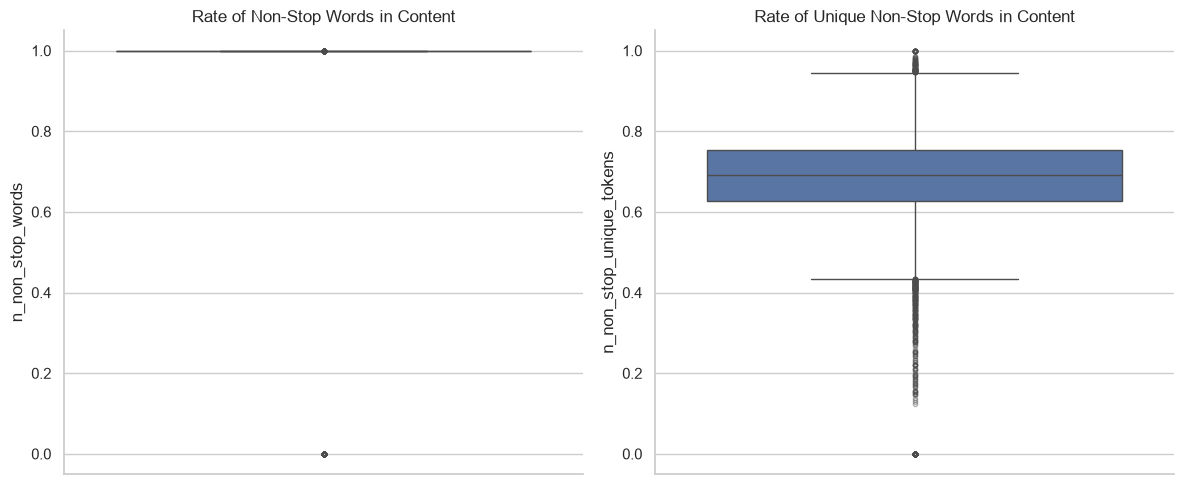

In [15]:
columns = ["n_non_stop_words", "n_non_stop_unique_tokens"]
titles = ["Rate of Non-Stop Words in Content", "Rate of Unique Non-Stop Words in Content"]
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, col, title in zip(axes, columns, titles):
    sns.boxplot(data=df, y=col, ax=ax, showfliers=True,
                flierprops={"marker": "o", "markersize": 3, "alpha": 0.4})
    ax.set_title(title)
    ax.set_ylabel(col)
sns.despine()
plt.tight_layout()
plt.show()

## Self-reference share features

Shares of other articles linked or referenced within each article. These are heavily skewed counts; use `log1p` for visualization without dropping zeros. Confirm the features were available at the intended prediction time.

,count,mean,std,min,25%,50%,75%,max
self_reference_min_shares,34959.0,4026.95,20110.82,0.0,638.0,1200.0,2600.00,843300.0
self_reference_max_shares,34959.0,10308.61,40998.05,0.0,1100.0,2800.0,7900.00,843300.0
self_reference_avg_shares,34959.0,6424.93,24588.09,0.0,978.0,2200.0,5166.67,843300.0


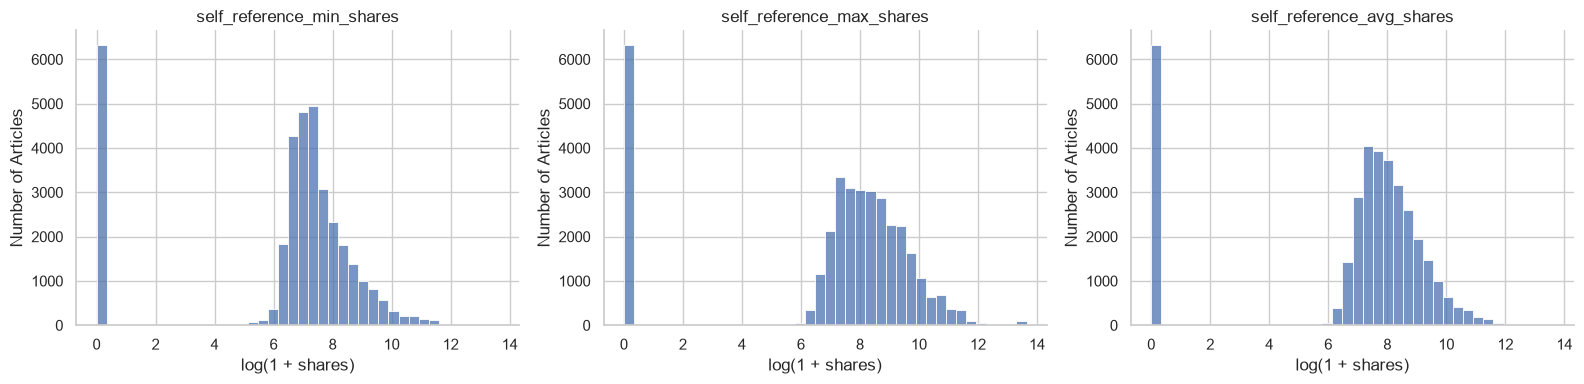

In [16]:
reference_features = ["self_reference_min_shares", "self_reference_max_shares", "self_reference_avg_shares"]
display(df[reference_features].describe().T.round(2))
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, reference_features):
    sns.histplot(np.log1p(df[col].clip(lower=0).dropna()), bins=40, ax=ax)
    ax.set_title(col)
    ax.set_xlabel("log(1 + shares)")
    ax.set_ylabel("Number of Articles")
sns.despine()
plt.tight_layout()
plt.show()

## Number of keywords

`num_keywords` counts keywords in the article metadata. Each bar shows the percentage of all articles.

,count,mean,std,min,25%,50%,75%,max
num_keywords,35680.0,7.220095,1.909604,1.0,6.0,7.0,9.0,10.0


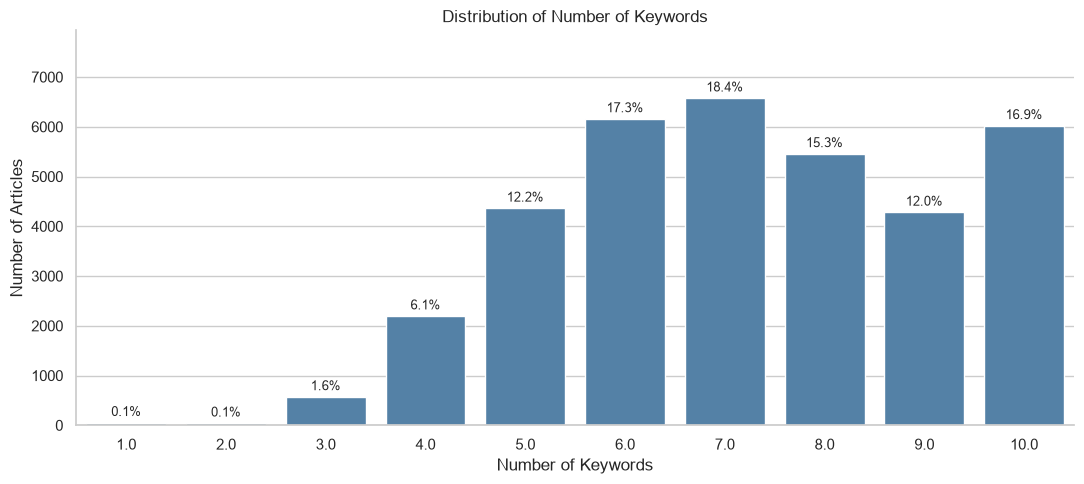

In [17]:
display(df[["num_keywords"]].describe().T)
order = sorted(df["num_keywords"].dropna().unique())
plt.figure(figsize=(11, 5))
ax = sns.countplot(data=df, x="num_keywords", order=order, color="steelblue")
for container in ax.containers:
    labels = [f"{bar.get_height() / len(df) * 100:.1f}%" if bar.get_height() else "" for bar in container]
    ax.bar_label(container, labels=labels, padding=3, fontsize=9)
ax.set_ylim(0, ax.get_ylim()[1] * 1.15)
ax.set_title("Distribution of Number of Keywords")
ax.set_xlabel("Number of Keywords")
ax.set_ylabel("Number of Articles")
sns.despine()
plt.tight_layout()
plt.show()

## Keyword historical share statistics

Nine `kw_*` features describe historical article-share statistics associated with the article’s keywords. Grouped below by the **second suffix** (`min`, `max`, `avg`), as in the dataset documentation. Note: the keyword history must be computed only from data available before publication to avoid leakage.

In [18]:
keyword_groups = {
    "Minimum-based keyword statistics": ["kw_min_min", "kw_max_min", "kw_avg_min"],
    "Maximum-based keyword statistics": ["kw_min_max", "kw_max_max", "kw_avg_max"],
    "Average-based keyword statistics": ["kw_min_avg", "kw_max_avg", "kw_avg_avg"],
}
keyword_features = [col for cols in keyword_groups.values() for col in cols]
display(df[keyword_features].describe().T.round(2))

,count,mean,std,min,25%,50%,75%,max
kw_min_min,35680.0,26.17,69.71,-1.0,-1.00,-1.00,4.00,377.00
kw_max_min,35680.0,1142.30,3844.83,0.0,445.00,658.00,1000.00,298400.00
kw_avg_min,35680.0,310.30,616.96,-1.0,141.44,235.43,357.00,42827.86
kw_min_max,35680.0,13533.50,57623.78,0.0,0.00,1400.00,7800.00,843300.00
kw_max_max,35680.0,752318.56,214391.92,0.0,843300.00,843300.00,843300.00,843300.00
kw_avg_max,35680.0,259143.79,135080.42,0.0,172595.65,244133.33,330980.00,843300.00
kw_min_avg,35680.0,1115.67,1136.74,-1.0,0.00,1020.67,2058.09,3610.12
kw_max_avg,35680.0,5637.98,6026.97,0.0,3559.65,4348.58,6015.43,298400.00
kw_avg_avg,35680.0,3130.80,1311.01,0.0,2379.76,2867.99,3595.53,43567.66


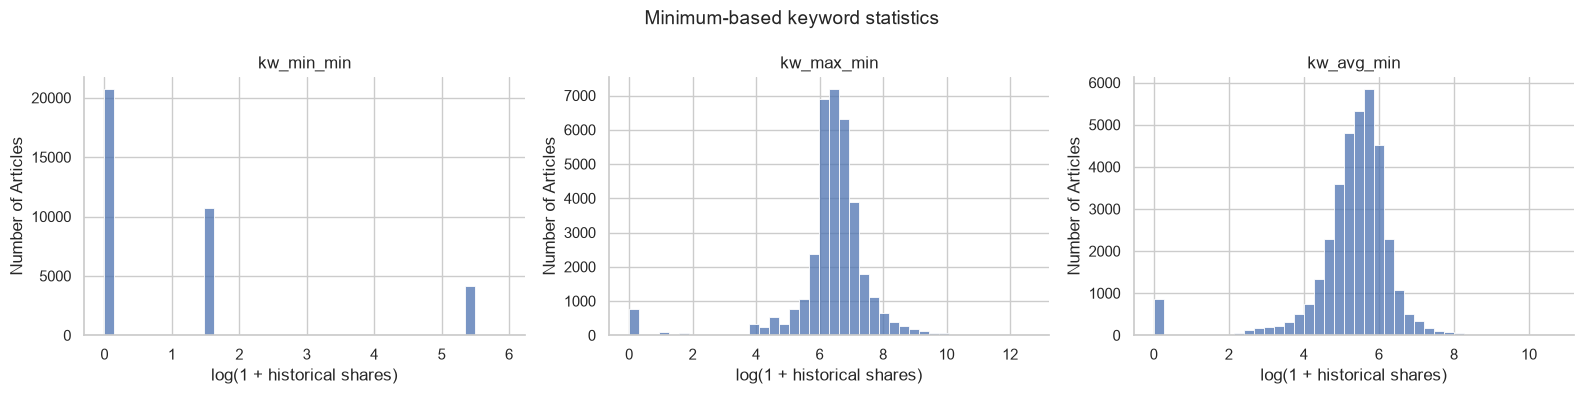

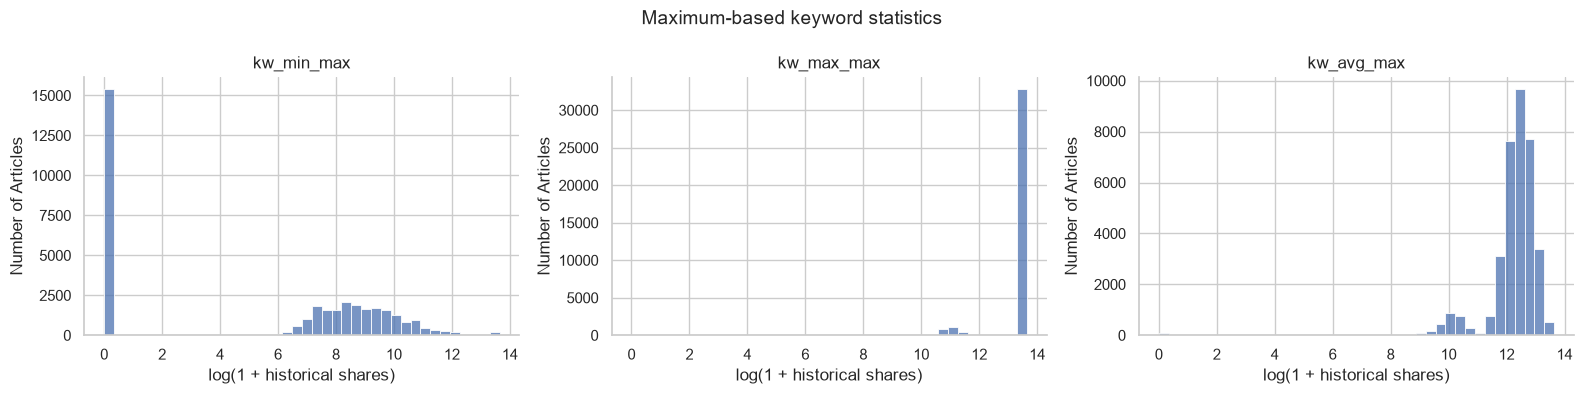

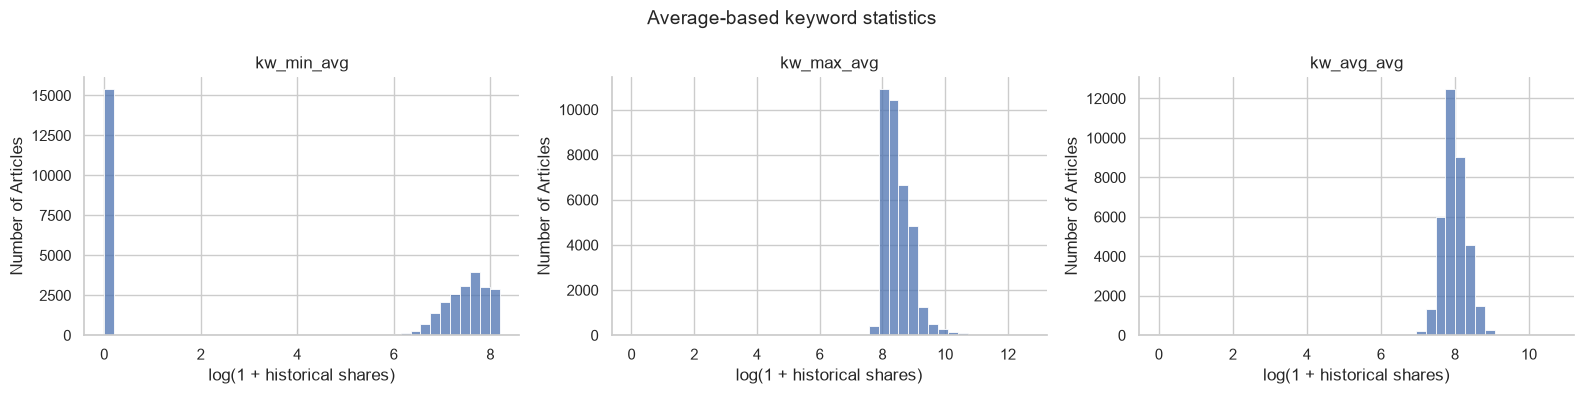

In [19]:
for group_name, columns in keyword_groups.items():
    fig, axes = plt.subplots(1, 3, figsize=(16, 4))
    for ax, col in zip(axes, columns):
        sns.histplot(np.log1p(df[col].clip(lower=0).dropna()), bins=40, ax=ax)
        ax.set_title(col)
        ax.set_xlabel("log(1 + historical shares)")
        ax.set_ylabel("Number of Articles")
    fig.suptitle(group_name, fontsize=14)
    sns.despine()
    plt.tight_layout()
    plt.show()